<H1>Example 4</H1> 
Learning how to use manim 
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 18-Oct-26 </td>
        <td> CBL </td> 
        <td> Original </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
References: <br> 
<a href="https://docs.manim.community/en/stable/index.html"> manim guide</a> <br> 
<a href="https://docs.manim.community/en/stable/examples.html"> manim examples</a>

<H2> Notes </H2>


In [3]:
# My imports
import numpy as np
import matplotlib.pyplot as plt
from manim import *

In [4]:
class BooleanOperations(Scene):
    def construct(self):
        ellipse1 = Ellipse(
            width=4.0, height=5.0, fill_opacity=0.5, color=BLUE, stroke_width=10
        ).move_to(LEFT)
        ellipse2 = ellipse1.copy().set_color(color=RED).move_to(RIGHT)
        bool_ops_text = MarkupText("<u>Boolean Operation</u>").next_to(ellipse1, UP * 3)
        ellipse_group = Group(bool_ops_text, ellipse1, ellipse2).move_to(LEFT * 3)
        self.play(FadeIn(ellipse_group))

        i = Intersection(ellipse1, ellipse2, color=GREEN, fill_opacity=0.5)
        self.play(i.animate.scale(0.25).move_to(RIGHT * 5 + UP * 2.5))
        intersection_text = Text("Intersection", font_size=23).next_to(i, UP)
        self.play(FadeIn(intersection_text))

        u = Union(ellipse1, ellipse2, color=ORANGE, fill_opacity=0.5)
        union_text = Text("Union", font_size=23)
        self.play(u.animate.scale(0.3).next_to(i, DOWN, buff=union_text.height * 3))
        union_text.next_to(u, UP)
        self.play(FadeIn(union_text))

        e = Exclusion(ellipse1, ellipse2, color=YELLOW, fill_opacity=0.5)
        exclusion_text = Text("Exclusion", font_size=23)
        self.play(e.animate.scale(0.3).next_to(u, DOWN, buff=exclusion_text.height * 3.5))
        exclusion_text.next_to(e, UP)
        self.play(FadeIn(exclusion_text))

        d = Difference(ellipse1, ellipse2, color=PINK, fill_opacity=0.5)
        difference_text = Text("Difference", font_size=23)
        self.play(d.animate.scale(0.3).next_to(u, LEFT, buff=difference_text.height * 3.5))
        difference_text.next_to(d, UP)
        self.play(FadeIn(difference_text))

In [5]:
manim -qm -v WARNING BooleanOperations

Manim Community v0.22.0

In [6]:
class PointMovingOnShapes(Scene):
    def construct(self):
        circle = Circle(radius=1, color=BLUE)
        dot = Dot()
        dot2 = dot.copy().shift(RIGHT)
        self.add(dot)

        line = Line([3, 0, 0], [5, 0, 0])
        self.add(line)

        self.play(GrowFromCenter(circle))
        self.play(Transform(dot, dot2))
        self.play(MoveAlongPath(dot, circle), run_time=2, rate_func=linear)
        self.play(Rotating(dot, about_point=[2, 0, 0]), run_time=1.5)
        self.wait()

In [7]:
manim -qm -v WARNING PointMovingOnShapes

Manim Community v0.22.0

In [8]:
class MovingAround(Scene):
    def construct(self):
        square = Square(color=BLUE, fill_opacity=1)

        self.play(square.animate.shift(LEFT))
        self.play(square.animate.set_fill(ORANGE))
        self.play(square.animate.scale(0.3))
        self.play(square.animate.rotate(0.4))

In [9]:
manim -qm -v WARNING MovingAround

Manim Community v0.22.0

In [10]:
class MovingAngle(Scene):
    def construct(self):
        rotation_center = LEFT

        theta_tracker = ValueTracker(110)
        line1 = Line(LEFT, RIGHT)
        line_moving = Line(LEFT, RIGHT)
        line_ref = line_moving.copy()
        line_moving.rotate(
            theta_tracker.get_value() * DEGREES, about_point=rotation_center
        )
        a = Angle(line1, line_moving, radius=0.5, other_angle=False)
        tex = MathTex(r"\theta").move_to(
            Angle(
                line1, line_moving, radius=0.5 + 3 * SMALL_BUFF, other_angle=False
            ).point_from_proportion(0.5)
        )

        self.add(line1, line_moving, a, tex)
        self.wait()

        line_moving.add_updater(
            lambda x: x.become(line_ref.copy()).rotate(
                theta_tracker.get_value() * DEGREES, about_point=rotation_center
            )
        )

        a.add_updater(
            lambda x: x.become(Angle(line1, line_moving, radius=0.5, other_angle=False))
        )
        tex.add_updater(
            lambda x: x.move_to(
                Angle(
                    line1, line_moving, radius=0.5 + 3 * SMALL_BUFF, other_angle=False
                ).point_from_proportion(0.5)
            )
        )

        self.play(theta_tracker.animate.set_value(40))
        self.play(theta_tracker.animate.increment_value(140))
        self.play(tex.animate.set_color(RED), run_time=0.5)
        self.play(theta_tracker.animate.set_value(350))

In [11]:
manim -qm -v WARNING MovingAngle

Manim Community v0.22.0

In [12]:
class MovingDots(Scene):
    def construct(self):
        d1,d2=Dot(color=BLUE),Dot(color=GREEN)
        dg=VGroup(d1,d2).arrange(RIGHT,buff=1)
        l1=Line(d1.get_center(),d2.get_center()).set_color(RED)
        x=ValueTracker(0)
        y=ValueTracker(0)
        d1.add_updater(lambda z: z.set_x(x.get_value()))
        d2.add_updater(lambda z: z.set_y(y.get_value()))
        l1.add_updater(lambda z: z.match_points(Line(d1.get_center(),d2.get_center())))
        self.add(d1,d2,l1)
        self.play(x.animate.set_value(5))
        self.play(y.animate.set_value(4))
        self.wait()

In [13]:
manim -qm -v WARNING MovingDots

Manim Community v0.22.0

In [14]:
class MovingFrameBox(Scene):
    def construct(self):
        text=MathTex(
            "\\frac{d}{dx}f(x)g(x)=","f(x)\\frac{d}{dx}g(x)","+",
            "g(x)\\frac{d}{dx}f(x)"
        )
        self.play(Write(text))
        framebox1 = SurroundingRectangle(text[1], buff = .1)
        framebox2 = SurroundingRectangle(text[3], buff = .1)
        self.play(
            Create(framebox1),
        )
        self.wait()
        self.play(
            ReplacementTransform(framebox1,framebox2),
        )
        self.wait()

In [15]:
manim -qm -v WARNING MovingFrameBox

Manim Community v0.22.0

In [16]:
class PointWithTrace(Scene):
    def construct(self):
        path = VMobject()
        dot = Dot()
        path.set_points_as_corners([dot.get_center(), dot.get_center()])
        def update_path(path):
            previous_path = path.copy()
            previous_path.add_points_as_corners([dot.get_center()])
            path.become(previous_path)
        path.add_updater(update_path)
        self.add(path, dot)
        self.play(Rotating(dot, angle=PI, about_point=RIGHT, run_time=2))
        self.wait()
        self.play(dot.animate.shift(UP))
        self.play(dot.animate.shift(LEFT))
        self.wait()

In [17]:
manim -qm -v WARNING PointWithTrace

Manim Community v0.22.0

In [18]:
class SinAndCosFunctionPlot(Scene):
    def construct(self):
        axes = Axes(
            x_range=[-10, 10.3, 1],
            y_range=[-1.5, 1.5, 1],
            x_length=10,
            axis_config={"color": GREEN},
            x_axis_config={
                "numbers_to_include": np.arange(-10, 10.01, 2),
                "numbers_with_elongated_ticks": np.arange(-10, 10.01, 2),
            },
            tips=False,
        )
        axes_labels = axes.get_axis_labels()
        sin_graph = axes.plot(lambda x: np.sin(x), color=BLUE)
        cos_graph = axes.plot(lambda x: np.cos(x), color=RED)

        sin_label = axes.get_graph_label(
            sin_graph, "\\sin(x)", x_val=-10, direction=UP / 2
        )
        cos_label = axes.get_graph_label(cos_graph, label="\\cos(x)")

        vert_line = axes.get_vertical_line(
            axes.i2gp(TAU, cos_graph), color=YELLOW, line_func=Line
        )
        line_label = axes.get_graph_label(
            cos_graph, r"x=2\pi", x_val=TAU, direction=UR, color=WHITE
        )

        plot = VGroup(axes, sin_graph, cos_graph, vert_line)
        labels = VGroup(axes_labels, sin_label, cos_label, line_label)
        self.add(plot, labels)

Manim Community v0.22.0

[10/18/26 20:26:25] WARNING  SinAndCosFunctionPlot has no play calls. Automatic video output has     ]8;id=5660731;file:///Users/christopherlirakis/.envJupyter/lib/python3.13/site-packages/manim/manager.py\manager.py]8;;\:]8;id=5660732;file:///Users/christopherlirakis/.envJupyter/lib/python3.13/site-packages/manim/manager.py#219\219]8;;\
                             been saved as a PNG instead.                                                          

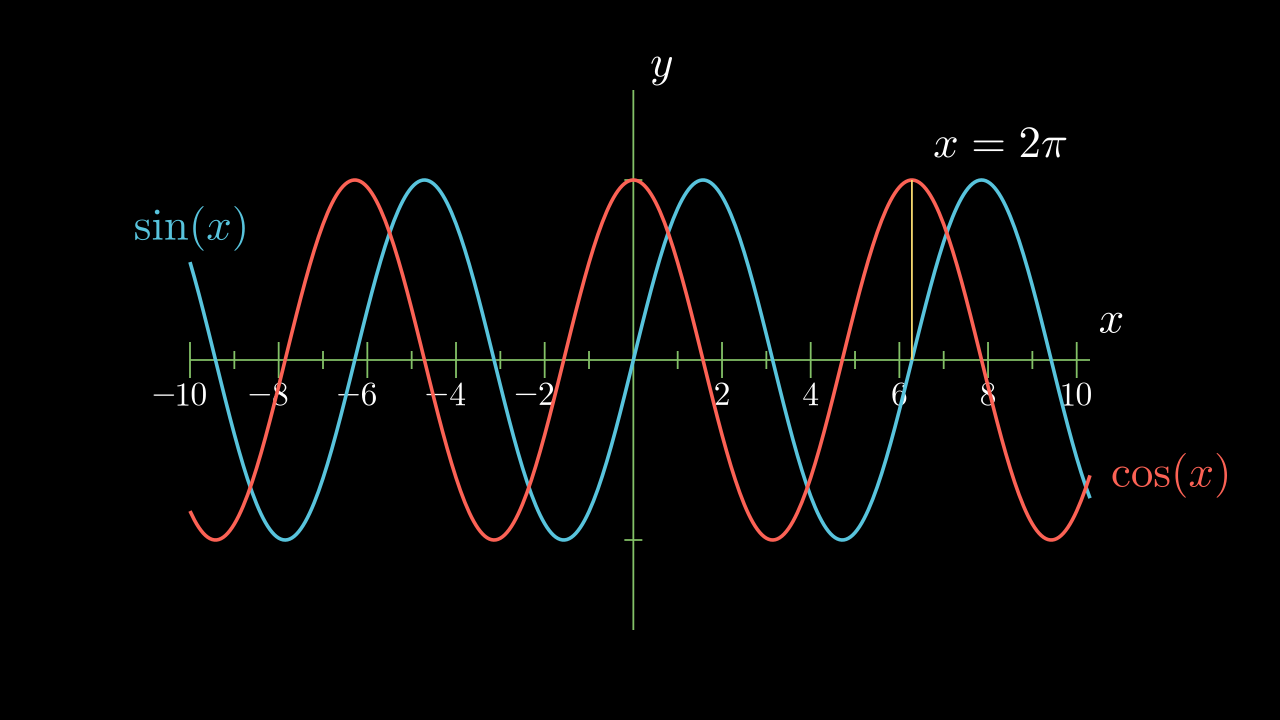

In [19]:
manim -qm -v WARNING SinAndCosFunctionPlot

In [20]:
class OpeningManim(Scene):
    def construct(self):
        title = Tex(r"This is some \LaTeX")
        basel = MathTex(r"\sum_{n=1}^\infty \frac{1}{n^2} = \frac{\pi^2}{6}")
        VGroup(title, basel).arrange(DOWN)
        self.play(
            Write(title),
            FadeIn(basel, shift=DOWN),
        )
        self.wait()

        transform_title = Tex("That was a transform")
        transform_title.to_corner(UP + LEFT)
        self.play(
            Transform(title, transform_title),
            LaggedStart(*[FadeOut(obj, shift=DOWN) for obj in basel]),
        )
        self.wait()

        grid = NumberPlane()
        grid_title = Tex("This is a grid", font_size=72)
        grid_title.move_to(transform_title)

        self.add(grid, grid_title)  # Make sure title is on top of grid
        self.play(
            FadeOut(title),
            FadeIn(grid_title, shift=UP),
            Create(grid, run_time=3, lag_ratio=0.1),
        )
        self.wait()

        grid_transform_title = Tex(
            r"That was a non-linear function \\ applied to the grid"
        )
        grid_transform_title.move_to(grid_title, UL)
        grid.prepare_for_nonlinear_transform()
        self.play(
            grid.animate.apply_function(
                lambda p: p
                          + np.array(
                    [
                        np.sin(p[1]),
                        np.sin(p[0]),
                        0,
                    ]
                )
            ),
            run_time=3,
        )
        self.wait()
        self.play(Transform(grid_title, grid_transform_title))
        self.wait()

In [21]:
manim -qm -v WARNING OpeningManim

Manim Community v0.22.0